In [1]:
'''
Regression Analysis

Date: 2023-10-18

Anita Taylor

'''

'\nRegression Analysis\n\nDate: 2023-10-18\n\nAnita Taylor\n\n'

In [2]:
'''
Source:
https://www.sfu.ca/~mjbrydon/tutorials/BAinPy/10_multiple_regression.html
'''

'\nSource:\nhttps://www.sfu.ca/~mjbrydon/tutorials/BAinPy/10_multiple_regression.html\n'

In [3]:
'''
Questions:


'''

'\nQuestions:\n\n\n'

In [1]:
import statsmodels.api as sm
import numpy as np
from sklearn.datasets import load_digits
from umap import UMAP
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [2]:
'''
Imput
'''

Datat = pd.read_csv('finalformofData.csv')
Datat.columns = Datat.columns.str.strip()
Datat['FD'] = Datat['PRECIPITATION']-Datat['Precip_Climatology']
Datat['HW'] = Datat['MAX_TEMP']-Datat['Tx_Climatology']
Datat['MT'] = Datat['MIN_TEMP']-Datat['Tn_Climatology']

def assign_group(aquifer_type):
    if aquifer_type in ['1a', '1b', '1c', '2', '3', '4a']:
        return '1'
    elif aquifer_type in ['4b', '4c']:
        return '2'
    elif aquifer_type in ['5a', '6a', '6b']:
        return '3'
    elif aquifer_type == '5b':
        return '4'
    else:
        return '5'
    
Datat['Aquifer Group'] = Datat['Aquifer Subtype'].apply(assign_group)
Datat = Datat.dropna()

DropDF1 = ['', 'Unnamed: 0.1', 'Unnamed: 0', 'LOCATION', 'History ID','Closest Longitude', 'Closest Latitude', 'Station ID', 'DATE_merged', 'Native ID', 'month', 'Station Name', 'EMS ID', 'Aquifer ID Number','Well Tag Number', 'year_month','Cd-T']
Datat = Datat.drop(DropDF1, axis=1, errors='ignore')

DropDF1b = ['Aquifer Subtype', 'Precip_Climatology', 'Tn_Climatology', 'Tx_Climatology' ]
Datat = Datat.drop(DropDF1b, axis=1, errors='ignore')

DropDF1c = ['OBSWELL']
Datat = Datat.drop(DropDF1c, axis=1, errors='ignore')

#Start encoding it.  Will Finish it later
one_hot_df = pd.get_dummies(Datat['Aquifer Group'], prefix='Aquifer')
Datat = pd.concat([Datat, one_hot_df], axis=1)

#Use a local Cartesian conversion to account for distance given it is very 'flat'.  Also should I reference Vancouver as the reference points?  They think they are the center of the world anyway

# Calculate the reference point
ref_latitude = Datat['LATITUTE'].mean()
ref_longitude = Datat['LONGITUDE'].mean()

# Convert the differences in latitude and longitude from the reference point into distances
Datat['x'] = (Datat['LONGITUDE'] - ref_longitude) * (111.412 * np.cos(np.radians(ref_latitude)) - 0.0935 * np.cos(3 * np.radians(ref_latitude)))
Datat['y'] = (Datat['LATITUTE'] - ref_latitude) * 111.132

DropDF2b = ['LONGITUDE','LATITUTE', 'Aquifer Group']
Datat = Datat.drop(DropDF2b, axis=1, errors='ignore')



#Decided to keep reference points the same
Datat['DATE'] = pd.to_datetime(Datat['DATE'])


Datawithtime = Datat.copy()

#Used "Time since event" - months since the first sampling time.  As this is sequencial, it has to be calculated in subsequent dataframes
Datat['Months_Since_First_Sample'] = ((Datat['DATE'] - Datat['DATE'].min()) / np.timedelta64(1, 'M')).round()
DropDF2a = ['DATE']
Datat = Datat.drop(DropDF2a, axis=1, errors='ignore')


Datat.columns






ValueError: Unit M is not supported. Only unambiguous timedelta values durations are supported. Allowed units are 'W', 'D', 'h', 'm', 's', 'ms', 'us', 'ns'

In [ ]:
'''
Handling Outliers

Notes:  
To prevent more outlier removal, use MAD score.  ID datat style.  Will not to Mahalanobis method due to complexity

Decided to use threshold score instead.  MAD scores takes away from metals being past the drinking water standard and SWI values

Source:
https://stats.stackexchange.com/questions/591853/interquartile-range-finding-more-than-10-times-outliers-than-zscore#:~:text=Yes%20%2D%20using%20the%20IQR%20method,will%20find%20lots%20of%20outliers.
https://saturncloud.io/blog/how-to-detect-and-exclude-outliers-in-a-pandas-dataframe/#:~:text=The%20IQR%20can%20be%20calculated,can%20be%20considered%20an%20outlier.
https://www.analyticsvidhya.com/blog/2021/05/detecting-and-treating-outliers-treating-the-odd-one-out/
'''

def replace_outliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        upper_threshold = Q3 + k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
        cleaned_dataset.loc[cleaned_dataset[col] > upper_threshold, col] = upper_threshold
    return cleaned_dataset

#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols1 = ['pH', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'K--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',  'Alkalinity Total 4.5', 'Hardness Total (T)', 'Residue Filterable 1.0u']
#Numeric_cols1a = ['Alkalinity Total 4.5', 'Hardness Total (T)','Residue Filterable 1.0u']
cleaned_dataset_array1 = replace_outliers_with_iqr(Datat[numeric_cols1], 1.5)
Datat[numeric_cols1] = cleaned_dataset_array1

def replace_loweroutliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
    return cleaned_dataset
numeric_cols1a = ['U--T']
cleaned_dataset_array1a = replace_outliers_with_iqr(Datat[numeric_cols1a], 1.5)
Datat[numeric_cols1a] = cleaned_dataset_array1a

def replace_outliers_with_threshold(dataset, threshold_multiplier=3):
    """
    Replace outliers in a dataset with the threshold value based on the Median Absolute Deviation (MAD).

    Parameters:
    - dataset: DataFrame containing the dataset.
    - threshold_multiplier: Multiple of the MAD to be used as the threshold (default: 3).

    Returns:
    - cleaned_dataset: DataFrame with outliers replaced by the threshold.
    """
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        col_values = cleaned_dataset[col].values
        median = np.median(col_values)
        mad = np.median(np.abs(col_values - median))
        lower_threshold = median - threshold_multiplier * mad
        upper_threshold = median + threshold_multiplier * mad
        outliers = (col_values - median) > upper_threshold
        cleaned_dataset.loc[outliers, col] = upper_threshold
        outliers = (col_values - median) < lower_threshold
        cleaned_dataset.loc[outliers, col] = lower_threshold
    return cleaned_dataset


In [ ]:
'''
Scaling

Source:
https://scikit-learn.org/stable/modules/preprocessing.html
https://stats.stackexchange.com/questions/402470/how-can-i-use-scaling-and-log-transforming-together

https://stackoverflow.com/questions/60998512/how-to-scale-all-columns-except-last-column
https://stackoverflow.com/questions/62997793/apply-standarization-to-all-columns-except-one-in-pandas
'''

from sklearn.preprocessing import PowerTransformer

# Create a PowerTransformer object
pt = PowerTransformer(method='yeo-johnson')

# Define the column names you want to transform
cols_to_transform = ['As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T',
       'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'pH', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT' , 'Alkalinity Total 4.5', 'Hardness Total (T)', 'Residue Filterable 1.0u']
# Apply the transformation to the specified columns
Datat[cols_to_transform] = pt.fit_transform(Datat[cols_to_transform])

In [ ]:
'''
Correlation matrix

Source: 

https://likegeeks.com/python-correlation-matrix/
https://medium.com/analytics-vidhya/kendall-rank-correlation-python-19524cb0e9a0

'''
# import pandas and numpy if they're not already imported
import pandas as pd
import numpy as np

#Dataset for Paper2 

df_Aq1 = Datat[Datat['Aquifer Group'] = 1]
df_Aq2 = Datat[Datat['Aquifer Group'] = 2]
df_Aq3 = Datat[Datat['Aquifer Group'] = 3]

correlation_matmain = Datat.corr()
correlation_matmain.to_csv('correlation_matafteroutliermainforpaper.csv')

correlation_mataq1 = df_Aq1.corr()
correlation_mataq1.to_csv('correlation_matafteroutlieraq1.csv')

correlation_mataq2 = df_Aq2.corr()
correlation_mataq2.to_csv('correlation_matafteroutlieraq2.csv')

correlation_mataq3 = df_Aq3.corr()
correlation_mataq3.to_csv('correlation_matafteroutlieraq3.csv')

correlation_taumain = Datat.corr(method='kendall')
correlation_taumain.to_csv('correlation_tauafteroutliermainforpaper.csv')

correlation_tauaq1 = df_Aq1.corr(method='kendall')
correlation_tauaq1.to_csv('correlation_tauafteroutlieraq1.csv')

correlation_tauaq2 = df_Aq2.corr(method='kendall')
correlation_tauaq2.to_csv('correlation_tauafteroutlieraq2.csv')

correlation_tauaq3 = df_Aq3.corr(method='kendall')
correlation_tauaq3.to_csv('correlation_tauafteroutlieraq3.csv')

correlation_rhoaqmain = Datat.corr(method='spearman')
correlation_rhoaqmain.to_csv('correlation_rhoafteroutliermainforpaper.csv')

correlation_rhoaq1 = df_Aq1.corr(method='spearman')
correlation_rhoaq1.to_csv('correlation_rhoafteroutlieraq1.csv')

correlation_rhoaq2 = df_Aq2.corr(method='spearman')
correlation_rhoaq2.to_csv('correlation_rhoafteroutlieraq2.csv')

correlation_rhoaq3 = df_Aq1.corr(method='spearman')
correlation_rhoaq3.to_csv('correlation_rhoafteroutlieraq3.csv')

In [5]:
import statsmodels.api as sm

# Define dependent and independent variables
Xa = Datat[['Alkalinity Total 4.5', 'Chlrid:D', 'Fe-T',
       'N.Kjel:T', 'P--T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T','PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 
        'FD', 'HW', 'MT', 'Aquifer_1', 'Aquifer_2', 'Aquifer_3', 'x', 'y', 'Months_Since_First_Sample']]
Xa = sm.add_constant(Xa)

# Compute and print the correlation matrix
con = Xa.corr()
print(round(con,2))

# Arsenic
Ya = Datat['As-T']
ksa = sm.OLS(Ya, Xa)
ksa_res = ksa.fit()
summary_ksa = ksa_res.summary().as_text()
with open('Stats/summary_ksa.txt', 'w') as f:
    f.write(summary_ksa)

# Manganese
Ym = Datat['Mn-T']
ksm = sm.OLS(Ym, Xa)
ksm_res =ksm.fit()
summary_ksm = ksm_res.summary().as_text()
with open('Stats/summary_ksm.txt', 'w') as f:
    f.write(summary_ksm)

# Lead
Yp = Datat['Pb-T']
ksp = sm.OLS(Yp, Xa)
ksp_res =ksp.fit()
summary_ksp = ksp_res.summary().as_text()
with open('Stats/summary_ksp.txt', 'w') as f:
    f.write(summary_ksp)

# Uranium
Yu = Datat['U--T']
ksu = sm.OLS(Yu, Xa)
ksu_res =ksu.fit()
summary_ksu = ksu_res.summary().as_text()
with open('Stats/summary_ksu.txt', 'w') as f:
    f.write(summary_ksu)


                           const  Alkalinity Total 4.5  Chlrid:D  Fe-T  \
const                        NaN                   NaN       NaN   NaN   
Alkalinity Total 4.5         NaN                  1.00      0.37 -0.08   
Chlrid:D                     NaN                  0.37      1.00  0.07   
Fe-T                         NaN                 -0.08      0.07  1.00   
N.Kjel:T                     NaN                  0.17      0.16  0.15   
P--T                         NaN                  0.12     -0.07  0.07   
Residue Filterable 1.0u      NaN                  0.74      0.53 -0.06   
Specific Conductance         NaN                  0.81      0.55 -0.09   
Sulfat:D                     NaN                  0.54      0.31 -0.15   
pH                           NaN                  0.53      0.03 -0.11   
Hardness Total (T)           NaN                  0.58      0.24 -0.06   
K--T                         NaN                  0.41      0.05  0.08   
PRECIPITATION                NaN      

                     variable  coefficient
0                       const     0.000000
1        Alkalinity Total 4.5     0.256670
2                    Chlrid:D    -0.203991
3                        Fe-T     0.183350
4                    N.Kjel:T    -0.058702
5                        P--T     0.180744
6     Residue Filterable 1.0u     0.061750
7        Specific Conductance    -0.118737
8                    Sulfat:D     0.148852
9                          pH     0.147643
10         Hardness Total (T)     0.196400
11                       K--T     0.121143
12              PRECIPITATION    -0.032651
13                   MIN_TEMP     0.057100
14                   MAX_TEMP    -0.068092
15                         FD     0.032318
16                         HW     0.004435
17                         MT    -0.034952
18                  Aquifer_1     0.104218
19                  Aquifer_2     0.008762
20                  Aquifer_3    -0.112980
21                          x    -0.001652
22         

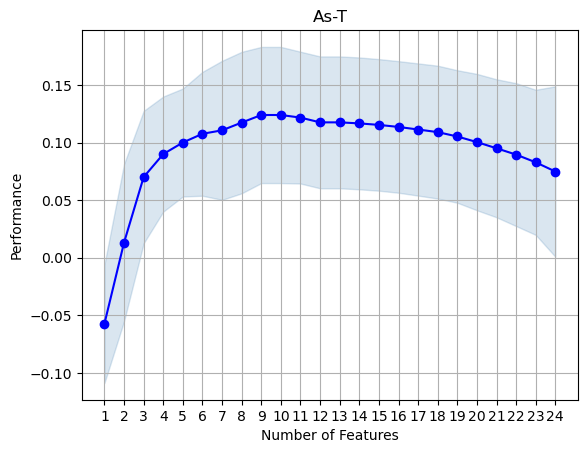

('const', 'Alkalinity Total 4.5', 'Chlrid:D', 'Fe-T', 'P--T', 'Sulfat:D', 'Hardness Total (T)', 'K--T', 'x', 'Months_Since_First_Sample')
0.12389640650093667


In [9]:
from sklearn.linear_model import LinearRegression
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
import matplotlib.pyplot as plt
import pandas as pd

mod = LinearRegression()
mod.fit(Xa,Ya)

coef = pd.concat([pd.Series(Xa.columns), pd.Series(mod.coef_)], axis=1)
coef.columns=["variable", "coefficient"]
print(coef)

sfs = SFS(mod,
         k_features='best',
         forward=False,
         floating=False,
         scoring='r2',
         cv=30)

sfs = sfs.fit(Xa,Ya)

print(pd.DataFrame.from_dict(sfs.get_metric_dict(confidence_interval=0.95)).T)

# Print the indices of the best features
print('Best feature indices:', sfs.k_feature_idx_)

# Print the names of the best features
print('Best features:', sfs.k_feature_names_)

# Print the score of the best features
print('Best score:', sfs.k_score_)

# Print a dictionary containing the feature subsets
print('Feature subsets:')
for subset in sfs.subsets_.values():
    print(subset)

fig1 = plot_sfs(sfs.get_metric_dict(), kind='std_err')
plt.grid()
plt.title("As-T") 
plt.show()

# Print the names of the features in the subset with 9 features
print(sfs.subsets_[10].get('feature_names'))

# Print the score of the subset with 9 features
print(sfs.subsets_[10].get('avg_score'))

In [10]:
import statsmodels.api as sm

# Get the names of the 9 best features
best_featuresas = list(sfs.subsets_[10].get('feature_names'))

# Select only the best features from your original dataset
X_bestas = Xa[best_featuresas]

# Add a constant to the predictors
X_best_smas = sm.add_constant(X_bestas)

# Fit the OLS model
modelas = sm.OLS(Ya, X_best_smas)
resultsas = modelas.fit()

# Print out the statistics
print(resultsas.summary())

                            OLS Regression Results                            
Dep. Variable:                   As-T   R-squared:                       0.314
Model:                            OLS   Adj. R-squared:                  0.308
Method:                 Least Squares   F-statistic:                     49.59
Date:                Fri, 22 Dec 2023   Prob (F-statistic):           6.33e-74
Time:                        12:35:33   Log-Likelihood:                -1212.0
No. Observations:                 985   AIC:                             2444.
Df Residuals:                     975   BIC:                             2493.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

                     variable  coefficient
0                       const     0.000000
1        Alkalinity Total 4.5     0.081904
2                    Chlrid:D    -0.059352
3                        Fe-T     0.524439
4                    N.Kjel:T     0.154990
5                        P--T     0.022053
6     Residue Filterable 1.0u    -0.155588
7        Specific Conductance    -0.032704
8                    Sulfat:D     0.024152
9                          pH     0.001788
10         Hardness Total (T)     0.397632
11                       K--T     0.084361
12              PRECIPITATION    -0.030013
13                   MIN_TEMP     0.316283
14                   MAX_TEMP    -0.330096
15                         FD     0.080581
16                         HW     0.134987
17                         MT    -0.125342
18                  Aquifer_1    -0.095425
19                  Aquifer_2    -0.029299
20                  Aquifer_3     0.124724
21                          x    -0.001498
22         

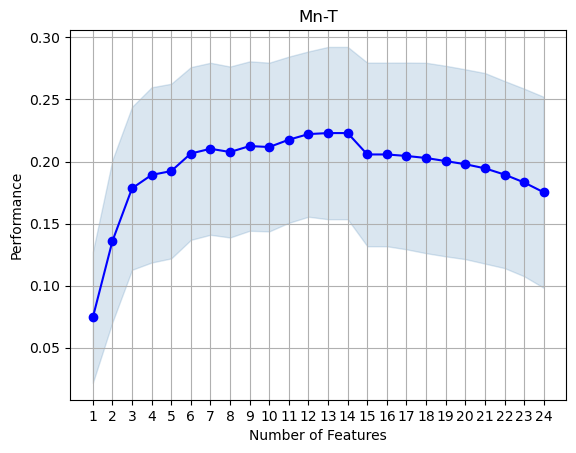

('const', 'Alkalinity Total 4.5', 'Fe-T', 'N.Kjel:T', 'Residue Filterable 1.0u', 'Hardness Total (T)', 'K--T', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT', 'Aquifer_1', 'x')
0.22294476890643555


In [11]:
from sklearn.linear_model import LinearRegression
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
import matplotlib.pyplot as plt
import pandas as pd

mod = LinearRegression()
mod.fit(Xa,Ym)

coef = pd.concat([pd.Series(Xa.columns), pd.Series(mod.coef_)], axis=1)
coef.columns=["variable", "coefficient"]
print(coef)

sfs = SFS(mod,
         k_features='best',
         forward=False,
         floating=False,
         scoring='r2',
         cv=30)

sfs = sfs.fit(Xa,Ym)

mtinteration = pd.DataFrame.from_dict(sfs.get_metric_dict(confidence_interval=0.95)).T

print(mtinteration)

# Print the indices of the best features
print('Best feature indices:', sfs.k_feature_idx_)

# Print the names of the best features
print('Best features:', sfs.k_feature_names_)

# Print the score of the best features
print('Best score:', sfs.k_score_)

# Print a dictionary containing the feature subsets
print('Feature subsets:')
for subset in sfs.subsets_.values():
    print(subset)

fig1 = plot_sfs(sfs.get_metric_dict(), kind='std_err')
plt.grid()
plt.title("Mn-T") 
plt.show()

# Print the names of the features in the subset with 9 features
print(sfs.subsets_[14].get('feature_names'))

# Print the score of the subset with 9 features
print(sfs.subsets_[14].get('avg_score'))
###

In [12]:
import statsmodels.api as sm

# Get the names of the 9 best features
best_featuresmn = list(sfs.subsets_[13].get('feature_names'))

# Select only the best features from your original dataset
X_bestmn = Xa[best_featuresmn]

# Add a constant to the predictors
X_best_smmn = sm.add_constant(X_bestmn)

# Fit the OLS model
modelmn = sm.OLS(Ym, X_best_smmn)
resultsmn = modelmn.fit()

# Print out the statistics
print(resultsmn.summary())

                            OLS Regression Results                            
Dep. Variable:                   Mn-T   R-squared:                       0.428
Model:                            OLS   Adj. R-squared:                  0.420
Method:                 Least Squares   F-statistic:                     55.88
Date:                Fri, 22 Dec 2023   Prob (F-statistic):          3.52e-108
Time:                        12:35:57   Log-Likelihood:                -1122.6
No. Observations:                 985   AIC:                             2273.
Df Residuals:                     971   BIC:                             2342.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

                     variable  coefficient
0                       const     0.000000
1        Alkalinity Total 4.5     0.059709
2                    Chlrid:D     0.047159
3                        Fe-T     0.131712
4                    N.Kjel:T     0.006338
5                        P--T    -0.054906
6     Residue Filterable 1.0u     0.177242
7        Specific Conductance    -0.119994
8                    Sulfat:D    -0.085997
9                          pH     0.059434
10         Hardness Total (T)     0.019080
11                       K--T    -0.080443
12              PRECIPITATION    -0.093528
13                   MIN_TEMP     0.059369
14                   MAX_TEMP    -0.024750
15                         FD     0.045682
16                         HW     0.016422
17                         MT     0.004041
18                  Aquifer_1     0.012088
19                  Aquifer_2     0.005352
20                  Aquifer_3    -0.017439
21                          x     0.000270
22         

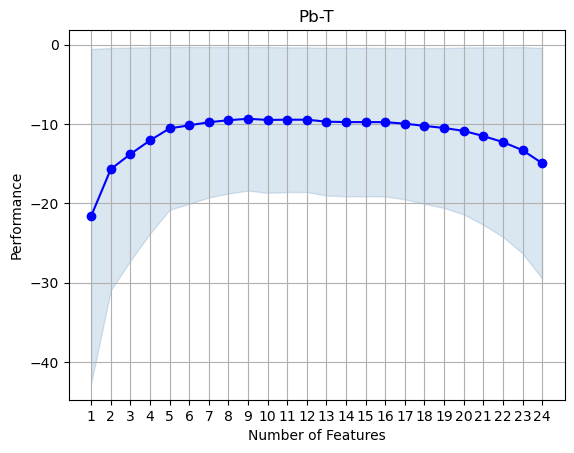

('Alkalinity Total 4.5', 'P--T', 'Residue Filterable 1.0u', 'Sulfat:D', 'pH', 'HW', 'x', 'y', 'Months_Since_First_Sample')
-9.345341838399177


In [6]:
from sklearn.linear_model import LinearRegression
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
import matplotlib.pyplot as plt
import pandas as pd

mod = LinearRegression()
mod.fit(Xa,Yp)

coef = pd.concat([pd.Series(Xa.columns), pd.Series(mod.coef_)], axis=1)
coef.columns=["variable", "coefficient"]
print(coef)

sfs = SFS(mod,
         k_features='best',
         forward=False,
         floating=False,
         scoring='r2',
         cv=30)

sfs = sfs.fit(Xa,Yp)

ptinteration = pd.DataFrame.from_dict(sfs.get_metric_dict(confidence_interval=0.95)).T

print(ptinteration)

# Print the indices of the best features
print('Best feature indices:', sfs.k_feature_idx_)

# Print the names of the best features
print('Best features:', sfs.k_feature_names_)

# Print the score of the best features
print('Best score:', sfs.k_score_)

# Print a dictionary containing the feature subsets
print('Feature subsets:')
for subset in sfs.subsets_.values():
    print(subset)

fig1 = plot_sfs(sfs.get_metric_dict(), kind='std_err')
plt.grid()
plt.title("Pb-T") 
plt.show()

# Print the names of the features in the subset with 9 features
print(sfs.subsets_[9].get('feature_names'))

# Print the score of the subset with 9 features
print(sfs.subsets_[9].get('avg_score'))
###

In [7]:
import statsmodels.api as sm

# Get the names of the 9 best features
best_featurespb = list(sfs.subsets_[11].get('feature_names'))

# Select only the best features from your original dataset
X_bestpb = Xa[best_featurespb]

# Add a constant to the predictors
X_best_smpb = sm.add_constant(X_bestpb)

# Fit the OLS model
modelpb = sm.OLS(Yp, X_best_smpb)
resultspb = modelpb.fit()

# Print out the statistics
print(resultspb.summary())

                            OLS Regression Results                            
Dep. Variable:                   Pb-T   R-squared:                       0.720
Model:                            OLS   Adj. R-squared:                  0.717
Method:                 Least Squares   F-statistic:                     227.2
Date:                Sun, 31 Dec 2023   Prob (F-statistic):          8.53e-260
Time:                        10:41:42   Log-Likelihood:                -771.06
No. Observations:                 985   AIC:                             1566.
Df Residuals:                     973   BIC:                             1625.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

                     variable  coefficient
0                       const     0.000000
1        Alkalinity Total 4.5     0.111752
2                    Chlrid:D    -0.087536
3                        Fe-T    -0.077955
4                    N.Kjel:T    -0.030312
5                        P--T     0.043298
6     Residue Filterable 1.0u    -0.114342
7        Specific Conductance    -0.145440
8                    Sulfat:D     0.211859
9                          pH     0.078198
10         Hardness Total (T)     0.316478
11                       K--T     0.067738
12              PRECIPITATION    -0.116687
13                   MIN_TEMP    -0.166433
14                   MAX_TEMP     0.111351
15                         FD     0.040474
16                         HW    -0.023211
17                         MT     0.075608
18                  Aquifer_1    -0.246988
19                  Aquifer_2    -0.109744
20                  Aquifer_3     0.356732
21                          x     0.000685
22         

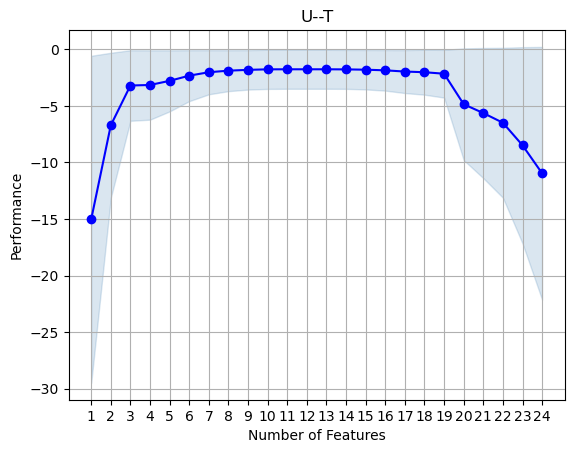

('N.Kjel:T', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'MT', 'Aquifer_1', 'Aquifer_2', 'x', 'y')
-1.8067188996344212


In [15]:
from sklearn.linear_model import LinearRegression
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
import matplotlib.pyplot as plt
import pandas as pd

mod = LinearRegression()
mod.fit(Xa,Yu)

coef = pd.concat([pd.Series(Xa.columns), pd.Series(mod.coef_)], axis=1)
coef.columns=["variable", "coefficient"]
print(coef)

sfs = SFS(mod,
         k_features='best',
         forward=False,
         floating=False,
         scoring='r2',
         cv=30)

sfs = sfs.fit(Xa,Yu)

utinteration = pd.DataFrame.from_dict(sfs.get_metric_dict(confidence_interval=0.95)).T

print(utinteration)

# Print the indices of the best features
print('Best feature indices:', sfs.k_feature_idx_)

# Print the names of the best features
print('Best features:', sfs.k_feature_names_)

# Print the score of the best features
print('Best score:', sfs.k_score_)

# Print a dictionary containing the feature subsets
print('Feature subsets:')
for subset in sfs.subsets_.values():
    print(subset)

fig1 = plot_sfs(sfs.get_metric_dict(), kind='std_err')
plt.grid()
plt.title("U--T") 
plt.show()

# Print the names of the features in the subset with 9 features
print(sfs.subsets_[9].get('feature_names'))

# Print the score of the subset with 9 features
print(sfs.subsets_[9].get('avg_score'))
###

In [16]:
import statsmodels.api as sm

# Get the names of the 9 best features
best_featuresu = list(sfs.subsets_[9].get('feature_names'))

# Select only the best features from your original dataset
X_bestu = Xa[best_featuresu]

# Add a constant to the predictors
X_best_smu = sm.add_constant(X_bestu)

# Fit the OLS model
modelu = sm.OLS(Yu, X_best_smu)
resultsu = modelu.fit()

# Print out the statistics
print(resultsu.summary())

                            OLS Regression Results                            
Dep. Variable:                   U--T   R-squared:                       0.349
Model:                            OLS   Adj. R-squared:                  0.343
Method:                 Least Squares   F-statistic:                     58.06
Date:                Fri, 22 Dec 2023   Prob (F-statistic):           7.79e-85
Time:                        12:37:41   Log-Likelihood:                -1186.3
No. Observations:                 985   AIC:                             2393.
Df Residuals:                     975   BIC:                             2442.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.4089      0.055      7.375      0.0

In [6]:
'''
SWI, Drought, Flood, Heatwave, Mintemp

numeric_cols1a = ['U--T']
cleaned_dataset_array1a = replace_outliers_with_iqr(Datat[numeric_cols1a], 1.5)
Datat[numeric_cols1a] = cleaned_dataset_array1a
'''
DropDF4a = ['FD', 'MT', 'HW', 'Hardness Total (T)']

DatatSWI =Datawithtime[(Datawithtime['Chlrid:D'] > 150) | (Datawithtime['Specific Conductance'] > 1000)]
DatatSWI['Months_Since_First_Sample'] = ((DatatSWI['DATE'] - DatatSWI['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatSWI = DatatSWI.drop(DropDF2a, axis=1, errors='ignore')

DatatDrought = Datawithtime[(Datawithtime['FD'] < 0)]
DatatDrought['Months_Since_First_Sample'] = ((DatatDrought['DATE'] - DatatDrought['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatDrought = DatatDrought.drop(DropDF2a, axis=1, errors='ignore')

DatatFlood = Datawithtime[(Datawithtime['FD'] > 0)]
DatatFlood['Months_Since_First_Sample'] = ((DatatFlood['DATE'] - DatatFlood['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatFlood = DatatFlood.drop(DropDF2a, axis=1, errors='ignore')

DatatHW = Datawithtime[(Datawithtime['HW'] > 0)]
DatatHW['Months_Since_First_Sample'] = ((DatatHW['DATE'] - DatatHW['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatHW = DatatHW.drop(DropDF2a, axis=1, errors='ignore')

DatatMT = Datawithtime[(Datawithtime['MT'] > 0)]
DatatMT['Months_Since_First_Sample'] = ((DatatMT['DATE'] - DatatMT['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatMT = DatatMT.drop(DropDF2a, axis=1, errors='ignore')


#cleaned_dataset_array2 = replace_outliers_with_iqr(DatatLatLong[numeric_cols1], 1.5)
#DatatLatLong[numeric_cols1] = cleaned_dataset_array2
#DatatLatLong[cols_to_transform] = pt.fit_transform(DatatLatLong[cols_to_transform])  

print(DatatSWI.shape[0])
print(DatatDrought.shape[0])

106
530


C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\1028252857.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DatatSWI['Months_Since_First_Sample'] = ((DatatSWI['DATE'] - DatatSWI['DATE'].min()) / np.timedelta64(1, 'M')).round()
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\1028252857.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DatatDrought['Months_Since_First_Sample'] = ((DatatDrought['DATE'] - DatatDrought['DATE'].min()) / np.timedelta64(1, 'M')).round()
C:\Users\Anita Taylo

In [7]:
numeric_cols1a = ['U--T']
cleaned_dataset_array1a = replace_outliers_with_iqr(Datat[numeric_cols1a], 1.5)
Datat[numeric_cols1a] = cleaned_dataset_array1a

#numeric_cols1 = ['pH', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'K--T',  'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT']
cleaned_dataset_array2i = replace_outliers_with_iqr(DatatSWI[numeric_cols1], 1.5)
DatatSWI[numeric_cols1] = cleaned_dataset_array2i
cleaned_dataset_array1ai = replace_outliers_with_iqr(DatatSWI[numeric_cols1a], 1.5)
DatatSWI[numeric_cols1a] = cleaned_dataset_array1ai
DatatSWI[cols_to_transform] = pt.fit_transform(DatatSWI[cols_to_transform])
DatatSWI = DatatSWI.drop(DropDF4a, axis=1, errors='ignore')

cleaned_dataset_array2ii = replace_outliers_with_iqr(DatatDrought[numeric_cols1], 1.5)
DatatDrought[numeric_cols1] = cleaned_dataset_array2ii
cleaned_dataset_array1aii = replace_outliers_with_iqr(DatatDrought[numeric_cols1a], 1.5)
DatatDrought[numeric_cols1a] = cleaned_dataset_array1aii
DatatDrought[cols_to_transform] = pt.fit_transform(DatatDrought[cols_to_transform])
DatatDrought = DatatDrought.drop(DropDF4a, axis=1, errors='ignore')
                                                          
cleaned_dataset_array2iii = replace_outliers_with_iqr(DatatFlood[numeric_cols1], 1.5)
DatatFlood[numeric_cols1] = cleaned_dataset_array2iii
cleaned_dataset_array1aiii = replace_outliers_with_iqr(DatatFlood[numeric_cols1a], 1.5)
DatatFlood[numeric_cols1a] = cleaned_dataset_array1aiii
DatatFlood[cols_to_transform] = pt.fit_transform(DatatFlood[cols_to_transform])
DatatFlood = DatatFlood.drop(DropDF4a, axis=1, errors='ignore')

cleaned_dataset_array2iv = replace_outliers_with_iqr(DatatHW[numeric_cols1], 1.5)
DatatHW[numeric_cols1] = cleaned_dataset_array2iv
cleaned_dataset_array1aiv = replace_outliers_with_iqr(DatatHW[numeric_cols1a], 1.5)
DatatHW[numeric_cols1a] = cleaned_dataset_array1aiv
DatatHW[cols_to_transform] = pt.fit_transform(DatatHW[cols_to_transform])
DatatHW = DatatHW.drop(DropDF4a, axis=1, errors='ignore')

cleaned_dataset_array2v = replace_outliers_with_iqr(DatatMT[numeric_cols1], 1.5)
DatatMT[numeric_cols1] = cleaned_dataset_array2v
cleaned_dataset_array1av = replace_outliers_with_iqr(DatatMT[numeric_cols1a], 1.5)
DatatMT[numeric_cols1a] = cleaned_dataset_array1av
DatatMT[cols_to_transform] = pt.fit_transform(DatatMT[cols_to_transform])
DatatMT = DatatMT.drop(DropDF4a, axis=1, errors='ignore')


DatatHW.columns


Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T',
       'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'K--T', 'U--T',
       'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'Aquifer_1', 'Aquifer_2',
       'Aquifer_3', 'x', 'y', 'Months_Since_First_Sample'],
      dtype='object')

In [8]:
print(DatatSWI.shape[0])
print(DatatDrought.shape[0])

106
530


In [18]:
DatatSWI.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T',
       'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'K--T', 'U--T',
       'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'Aquifer_1', 'Aquifer_2',
       'Aquifer_3', 'x', 'y', 'Months_Since_First_Sample'],
      dtype='object')

In [10]:
Asdrop = ['U--T','Pb-T','Mn-T']
Mndrop = ['As-T','Pb-T','U--T']
Pbdrop = ['As-T','U--T','Mn-T']
Udrop = ['As-T','Pb-T','Mn-T']
AsOther =DatatSWI.drop(Asdrop, axis=1, errors='ignore')
MnOther= DatatSWI.drop(Mndrop, axis=1, errors='ignore')
PbOther= DatatSWI.drop(Pbdrop, axis=1, errors='ignore')
UOther = DatatSWI.drop(Udrop, axis=1, errors='ignore')
AsOther.columns = AsOther.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
MnOther.columns = AsOther.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
PbOther.columns = AsOther.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
UOther.columns = AsOther.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
MnOther.columns

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\4162724381.py:9: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  AsOther.columns = AsOther.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\4162724381.py:10: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  MnOther.columns = AsOther.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\4162724381.py:11: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character 

Index(['Alkalinity_Total_4_5', 'As_T', 'Ca_T', 'Chlrid_D', 'Fe_T', 'N_Kjel_T',
       'P__T', 'Residue_Filterable_1_0u', 'Specific_Conductance', 'Sulfat_D',
       'pH', 'K__T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'Aquifer_1',
       'Aquifer_2', 'Aquifer_3', 'x', 'y', 'Months_Since_First_Sample'],
      dtype='object')

### Fix the syntax starting here

In [11]:
""" 
SWI Data

This is what you want to add in to the  smf.old(As-t ~)
Alkalinity Total 4.5 + Chlrid:D + Fe-T + N.Kjel:T + P--T + Residue Filterable 1.0u + Specific Conductance + Sulfat:D + pH + Hardness Total (T) + K--T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample'

"""

import statsmodels.formula.api as smf

Asdrop = ['U--T','Pb-T','Mn-T']
Mndrop = ['As-T','Pb-T','U--T']
Pbdrop = ['As-T','U--T','Mn-T']
Udrop = ['As-T','Pb-T','Mn-T']
AsOther =DatatSWI.drop(Asdrop, axis=1, errors='ignore')
MnOther= DatatSWI.drop(Mndrop, axis=1, errors='ignore')
PbOther= DatatSWI.drop(Pbdrop, axis=1, errors='ignore')
UOther = DatatSWI.drop(Udrop, axis=1, errors='ignore')
AsOther.columns = AsOther.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
MnOther.columns = MnOther.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
PbOther.columns = PbOther.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
UOther.columns = UOther.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')

ksa1 =  smf.ols('As_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=AsOther)
ksa1_res = ksa1.fit()
#ksa1_res.summary()

ksm1 =  smf.ols('Mn_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=MnOther)
ksm1_res = ksm1.fit()
ksm1_res.summary()
ksp1 =  smf.ols('Pb_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=PbOther)
ksp1_res = ksp1.fit()
#ksp1_res.summary()

ksu1 =  smf.ols('U__T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=UOther)
ksu1_res = ksu1.fit()
#ksu1_res.summary()

print("SWI Summary of ksa1 model:\n", ksa1_res.summary())
print("SWI Summary of ksm1 model:\n", ksm1_res.summary())
print("SWI nSummary of ksp1 model:\n", ksp1_res.summary())
print("SWI Summary of ksu1 model:\n", ksu1_res.summary())

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\1996513717.py:19: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  AsOther.columns = AsOther.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\1996513717.py:20: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  MnOther.columns = MnOther.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\1996513717.py:21: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character

SWI Summary of ksa1 model:
                             OLS Regression Results                            
Dep. Variable:                   As_T   R-squared:                       0.574
Model:                            OLS   Adj. R-squared:                  0.486
Method:                 Least Squares   F-statistic:                     6.523
Date:                Wed, 27 Dec 2023   Prob (F-statistic):           6.86e-10
Time:                        14:02:17   Log-Likelihood:                -105.13
No. Observations:                 106   AIC:                             248.3
Df Residuals:                      87   BIC:                             298.9
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\3577768394.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ksa1_res.resid, fit=stats.norm, ax=ax[0,0])
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\3577768394.py:10: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ksm1_res.re

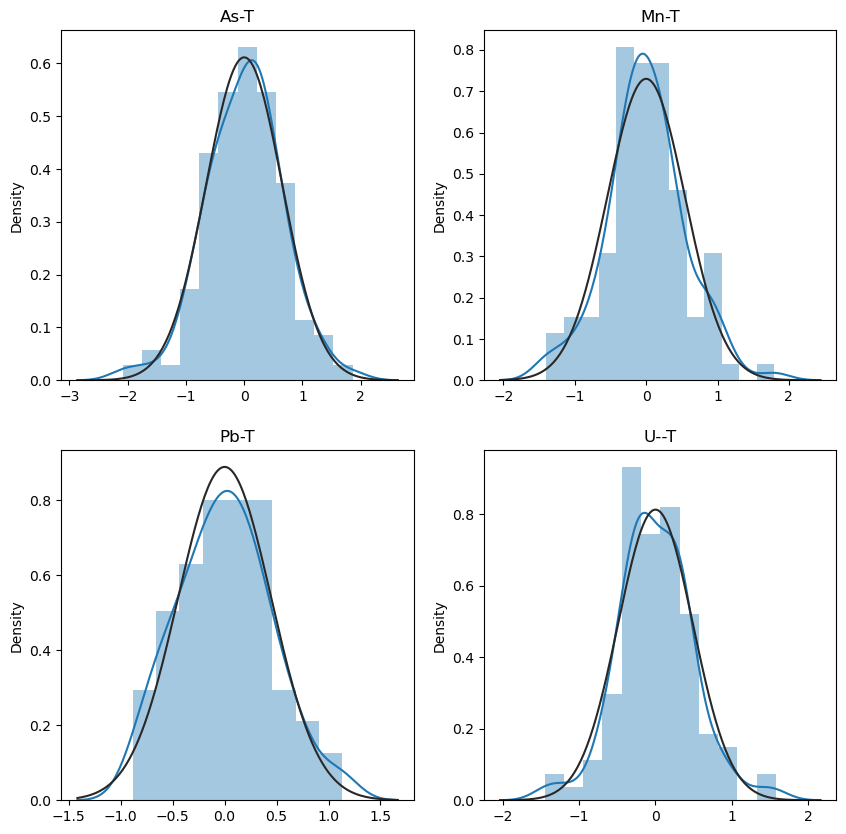

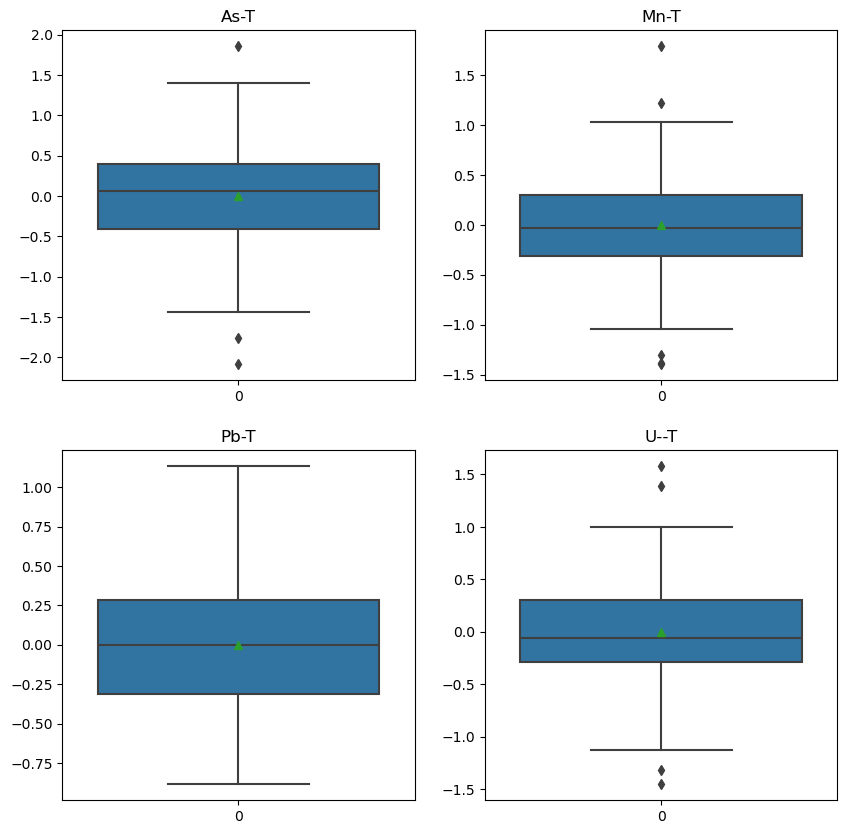

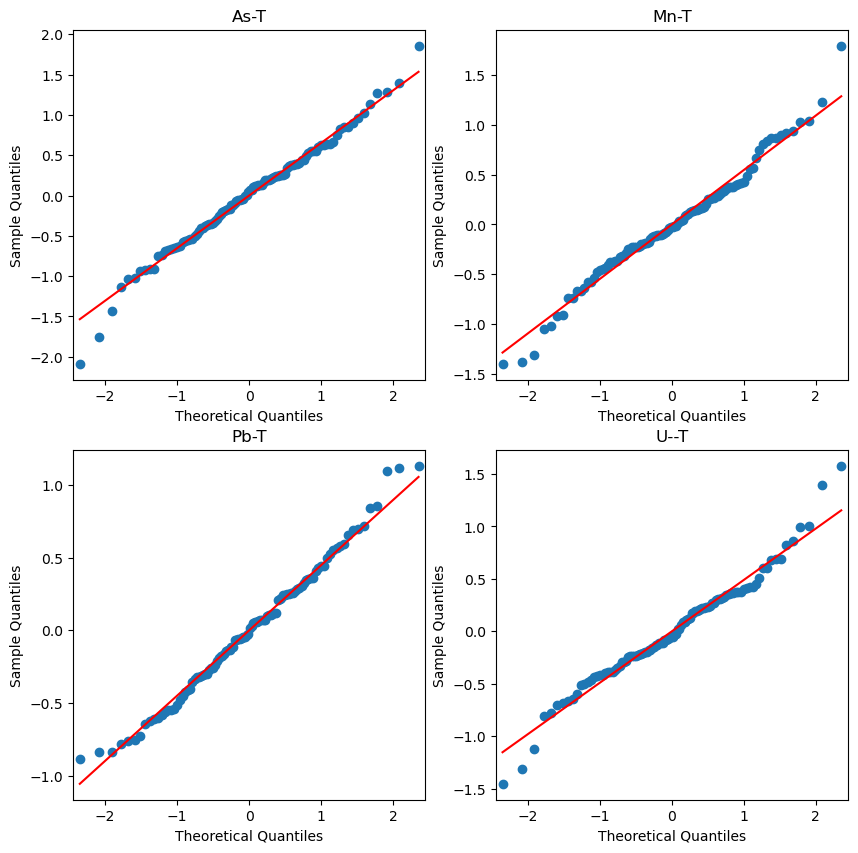

In [12]:
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Plot each set of residuals
fig, ax = plt.subplots(2, 2, figsize=(10,10))

sns.distplot(ksa1_res.resid, fit=stats.norm, ax=ax[0,0])
sns.distplot(ksm1_res.resid, fit=stats.norm, ax=ax[0,1]) 
sns.distplot(ksp1_res.resid, fit=stats.norm, ax=ax[1,0])
sns.distplot(ksu1_res.resid, fit=stats.norm, ax=ax[1,1])

ax[0,0].set_title('As-T')
ax[0,1].set_title('Mn-T')
ax[1,0].set_title('Pb-T') 
ax[1,1].set_title('U--T')

plt.show()

# Boxplots
fig, ax = plt.subplots(2, 2, figsize=(10,10))

sns.boxplot(ksa1_res.resid, showmeans=True, ax=ax[0,0])
sns.boxplot(ksm1_res.resid, showmeans=True, ax=ax[0,1])
sns.boxplot(ksp1_res.resid, showmeans=True, ax=ax[1,0])
sns.boxplot(ksu1_res.resid, showmeans=True, ax=ax[1,1])

ax[0,0].set_title('As-T')
ax[0,1].set_title('Mn-T')
ax[1,0].set_title('Pb-T') 
ax[1,1].set_title('U--T')

plt.show()

# QQPlots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(10,10))

sm.qqplot(ksa1_res.resid, line='s', ax=ax1)
sm.qqplot(ksm1_res.resid, line='s', ax=ax2)
sm.qqplot(ksp1_res.resid, line='s', ax=ax3)
sm.qqplot(ksu1_res.resid, line='s', ax=ax4)

ax1.set_title('As-T')
ax2.set_title('Mn-T')
ax3.set_title('Pb-T') 
ax4.set_title('U--T')

plt.show()


In [13]:
'''
Drought 
'''
Asdrop = ['U--T','Pb-T','Mn-T']
Mndrop = ['As-T','Pb-T','U--T']
Pbdrop = ['As-T','U--T','Mn-T']
Udrop = ['As-T','Pb-T','Mn-T']
AsOther2 =DatatDrought.drop(Asdrop, axis=1, errors='ignore')
MnOther2= DatatDrought.drop(Mndrop, axis=1, errors='ignore')
PbOther2= DatatDrought.drop(Pbdrop, axis=1, errors='ignore')
UOther2 = DatatDrought.drop(Udrop, axis=1, errors='ignore')
AsOther2.columns = AsOther2.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
MnOther2.columns = MnOther2.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
PbOther2.columns = PbOther2.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
UOther2.columns = UOther2.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')


ksa2 =  smf.ols('As_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=AsOther2)
ksa2_res = ksa2.fit()
#ksa1_res.summary()

ksm2 =  smf.ols('Mn_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=MnOther2)
ksm2_res = ksm2.fit()

ksp2 =  smf.ols('Pb_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=PbOther2)
ksp2_res = ksp2.fit()
#ksp1_res.summary()

ksu2 =  smf.ols('U__T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=UOther2)
ksu2_res = ksu2.fit()
#ksu1_res.summary()

print("Drought Summary of ksa2 model:\n", ksa2_res.summary())
print("Drought Summary of ksm2 model:\n", ksm2_res.summary())
print("Drought Summary of ksp2 model:\n", ksp2_res.summary())
print("Drought Summary of ksu2 model:\n", ksu2_res.summary())


Drought Summary of ksa2 model:
                             OLS Regression Results                            
Dep. Variable:                   As_T   R-squared:                       0.358
Model:                            OLS   Adj. R-squared:                  0.335
Method:                 Least Squares   F-statistic:                     15.83
Date:                Wed, 27 Dec 2023   Prob (F-statistic):           9.70e-39
Time:                        14:02:31   Log-Likelihood:                -634.58
No. Observations:                 530   AIC:                             1307.
Df Residuals:                     511   BIC:                             1388.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\2413568506.py:12: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  AsOther2.columns = AsOther2.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\2413568506.py:13: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  MnOther2.columns = MnOther2.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\2413568506.py:14: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single chara

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\1867062132.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ksa2_res.resid, fit=stats.norm, ax=ax[0,0])
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\1867062132.py:10: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ksm2_res.re

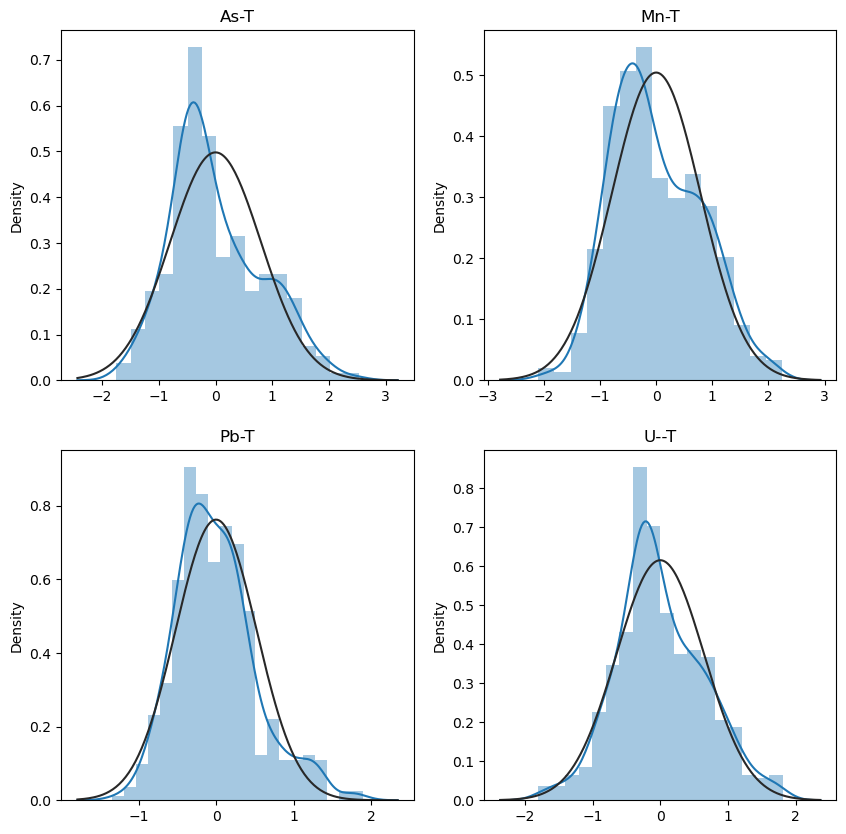

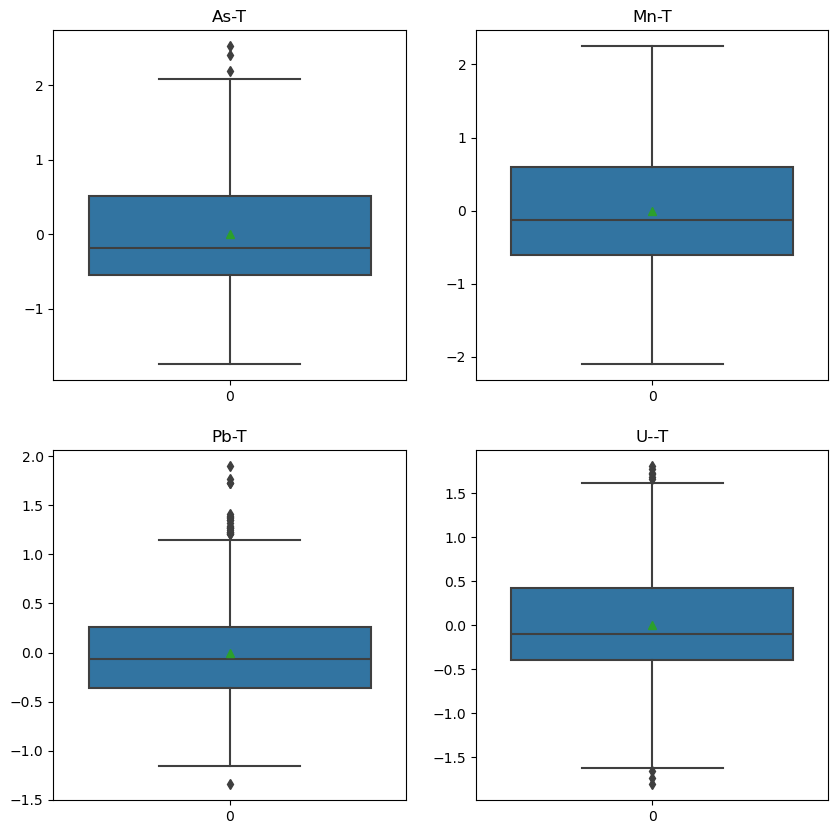

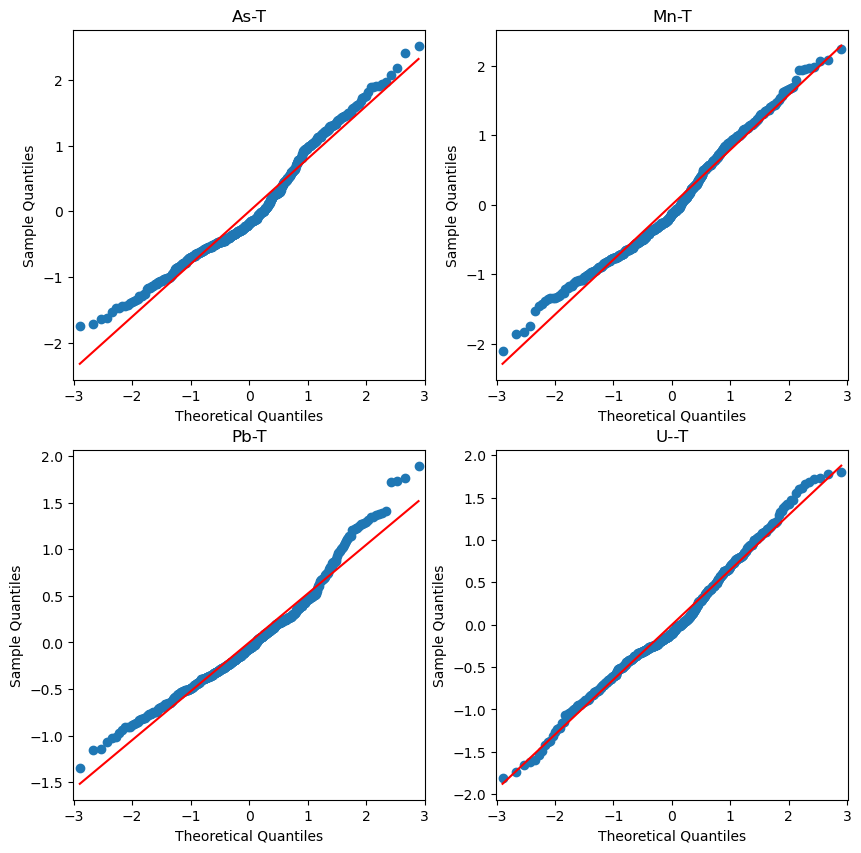

In [14]:
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Plot each set of residuals
fig, ax = plt.subplots(2, 2, figsize=(10,10))

sns.distplot(ksa2_res.resid, fit=stats.norm, ax=ax[0,0])
sns.distplot(ksm2_res.resid, fit=stats.norm, ax=ax[0,1]) 
sns.distplot(ksp2_res.resid, fit=stats.norm, ax=ax[1,0])
sns.distplot(ksu2_res.resid, fit=stats.norm, ax=ax[1,1])

ax[0,0].set_title('As-T')
ax[0,1].set_title('Mn-T')
ax[1,0].set_title('Pb-T') 
ax[1,1].set_title('U--T')

plt.show()

# Boxplots
fig, ax = plt.subplots(2, 2, figsize=(10,10))

sns.boxplot(ksa2_res.resid.reset_index(drop=True), showmeans=True, ax=ax[0,0])
sns.boxplot(ksm2_res.resid.reset_index(drop=True), showmeans=True, ax=ax[0,1])
sns.boxplot(ksp2_res.resid.reset_index(drop=True), showmeans=True, ax=ax[1,0])
sns.boxplot(ksu2_res.resid.reset_index(drop=True), showmeans=True, ax=ax[1,1])

ax[0,0].set_title('As-T')
ax[0,1].set_title('Mn-T')
ax[1,0].set_title('Pb-T') 
ax[1,1].set_title('U--T')

plt.show()

# QQPlots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(10,10))

sm.qqplot(ksa2_res.resid, line='s', ax=ax1)
sm.qqplot(ksm2_res.resid, line='s', ax=ax2)
sm.qqplot(ksp2_res.resid, line='s', ax=ax3)
sm.qqplot(ksu2_res.resid, line='s', ax=ax4)

ax1.set_title('As-T')
ax2.set_title('Mn-T')
ax3.set_title('Pb-T') 
ax4.set_title('U--T')

plt.show()


In [15]:
'''
Flood
'''
Asdrop = ['U--T','Pb-T','Mn-T']
Mndrop = ['As-T','Pb-T','U--T']
Pbdrop = ['As-T','U--T','Mn-T']
Udrop = ['As-T','Pb-T','Mn-T']
AsOther3 =DatatFlood.drop(Asdrop, axis=1, errors='ignore')
MnOther3= DatatFlood.drop(Mndrop, axis=1, errors='ignore')
PbOther3= DatatFlood.drop(Pbdrop, axis=1, errors='ignore')
UOther3 = DatatFlood.drop(Udrop, axis=1, errors='ignore')
AsOther3.columns = AsOther3.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
MnOther3.columns = MnOther3.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
PbOther3.columns = PbOther3.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
UOther3.columns = UOther3.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')


ksa3 =  smf.ols('As_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=AsOther3)
ksa3_res = ksa3.fit()
#ksa1_res.summary()

ksm3 =  smf.ols('Mn_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=MnOther3)
ksm3_res = ksm3.fit()

ksp3 =  smf.ols('Pb_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=PbOther3)
ksp3_res = ksp3.fit()
#ksp1_res.summary()

ksu3 =  smf.ols('U__T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=UOther3)
ksu3_res = ksu3.fit()
#ksu1_res.summary()

print("Flood Summary of ksa3 model:\n", ksa3_res.summary())
print("Flood Summary of ksm3 model:\n", ksm3_res.summary())
print("Flood Summary of ksp3 model:\n", ksp3_res.summary())
print("Flood Summary of ksu3 model:\n", ksu3_res.summary())

Flood Summary of ksa3 model:
                             OLS Regression Results                            
Dep. Variable:                   As_T   R-squared:                       0.328
Model:                            OLS   Adj. R-squared:                  0.301
Method:                 Least Squares   F-statistic:                     11.85
Date:                Wed, 27 Dec 2023   Prob (F-statistic):           4.39e-28
Time:                        14:03:03   Log-Likelihood:                -555.04
No. Observations:                 455   AIC:                             1148.
Df Residuals:                     436   BIC:                             1226.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\670362878.py:12: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  AsOther3.columns = AsOther3.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\670362878.py:13: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  MnOther3.columns = MnOther3.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\670362878.py:14: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single characte

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\2330508438.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ksa3_res.resid, fit=stats.norm, ax=ax[0,0])
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\2330508438.py:10: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ksm3_res.re

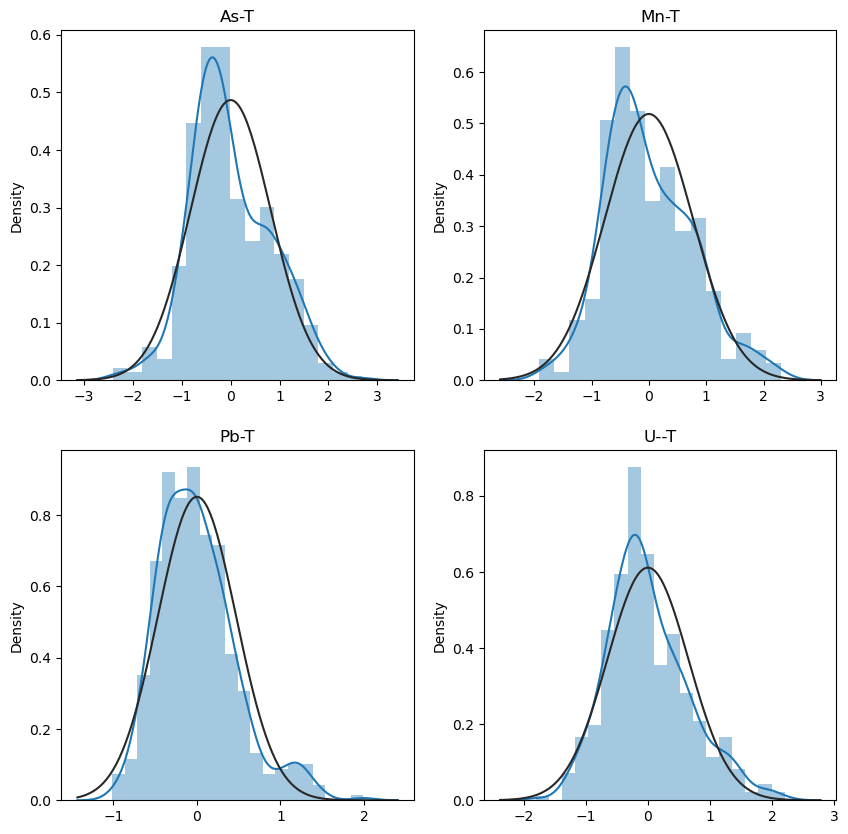

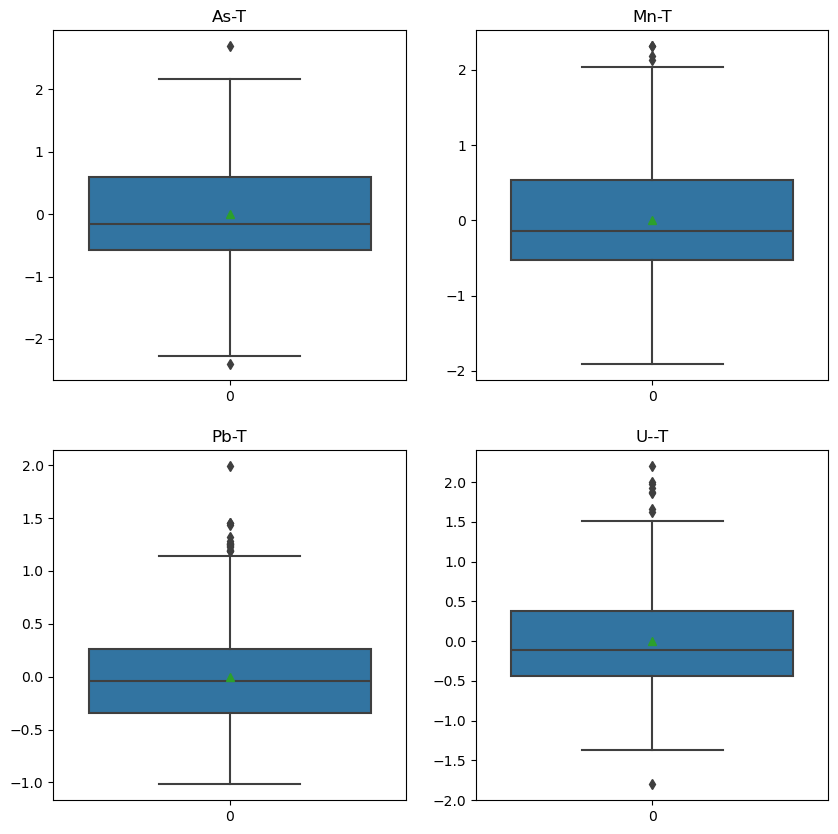

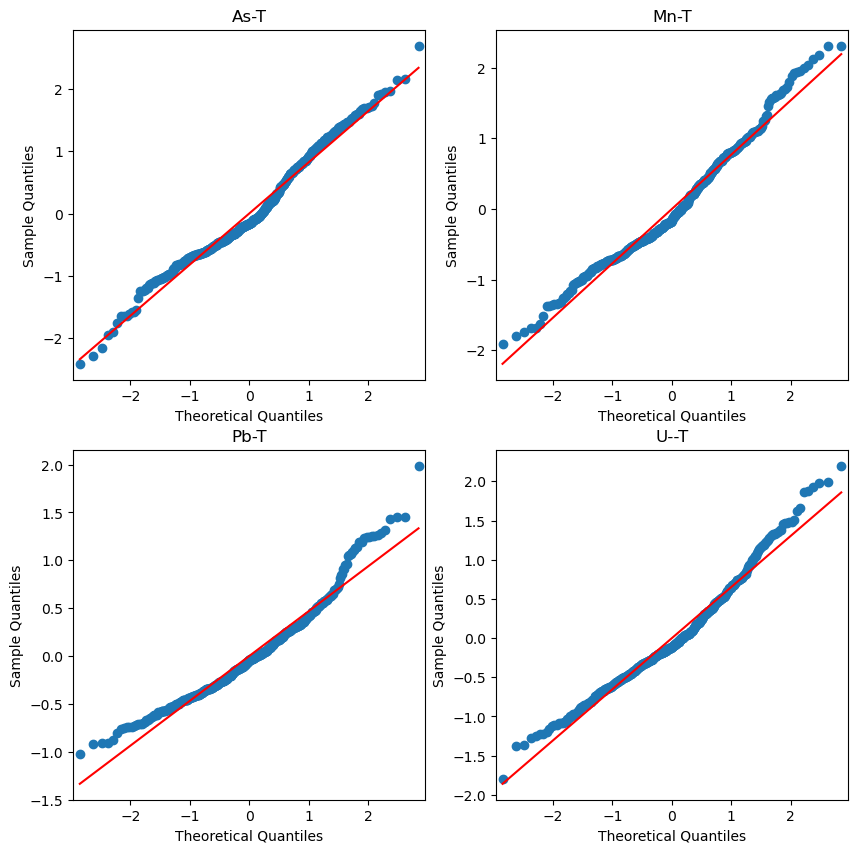

Text(0.5, 1.0, 'U--T')

In [16]:
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Plot each set of residuals
fig, ax = plt.subplots(2, 2, figsize=(10,10))

sns.distplot(ksa3_res.resid, fit=stats.norm, ax=ax[0,0])
sns.distplot(ksm3_res.resid, fit=stats.norm, ax=ax[0,1]) 
sns.distplot(ksp3_res.resid, fit=stats.norm, ax=ax[1,0])
sns.distplot(ksu3_res.resid, fit=stats.norm, ax=ax[1,1])

ax[0,0].set_title('As-T')
ax[0,1].set_title('Mn-T')
ax[1,0].set_title('Pb-T') 
ax[1,1].set_title('U--T')

plt.show()

# Boxplots
fig, ax = plt.subplots(2, 2, figsize=(10,10))

sns.boxplot(ksa3_res.resid.reset_index(drop=True), showmeans=True, ax=ax[0,0])
sns.boxplot(ksm3_res.resid.reset_index(drop=True), showmeans=True, ax=ax[0,1])
sns.boxplot(ksp3_res.resid.reset_index(drop=True), showmeans=True, ax=ax[1,0])
sns.boxplot(ksu3_res.resid.reset_index(drop=True), showmeans=True, ax=ax[1,1])

ax[0,0].set_title('As-T')
ax[0,1].set_title('Mn-T')
ax[1,0].set_title('Pb-T') 
ax[1,1].set_title('U--T')

plt.show()

# QQPlots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(10,10))

sm.qqplot(ksa3_res.resid, line='s', ax=ax1)
sm.qqplot(ksm3_res.resid, line='s', ax=ax2)
sm.qqplot(ksp3_res.resid, line='s', ax=ax3)
sm.qqplot(ksu3_res.resid, line='s', ax=ax4)

ax1.set_title('As-T')
ax2.set_title('Mn-T')
ax3.set_title('Pb-T') 
ax4.set_title('U--T')

plt.show()
ax[1,1].set_title('U--T')


In [17]:
'''
Max temp
'''
Asdrop = ['U--T','Pb-T','Mn-T']
Mndrop = ['As-T','Pb-T','U--T']
Pbdrop = ['As-T','U--T','Mn-T']
Udrop = ['As-T','Pb-T','Mn-T']
AsOther4 =DatatHW.drop(Asdrop, axis=1, errors='ignore')
MnOther4= DatatHW.drop(Mndrop, axis=1, errors='ignore')
PbOther4= DatatHW.drop(Pbdrop, axis=1, errors='ignore')
UOther4 = DatatHW.drop(Udrop, axis=1, errors='ignore')
AsOther4.columns = AsOther4.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
MnOther4.columns = MnOther4.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
PbOther4.columns = PbOther4.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
UOther4.columns = UOther4.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')


ksa4 =  smf.ols('As_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=AsOther4)
ksa4_res = ksa4.fit()
#ksa1_res.summary()

ksm4 =  smf.ols('Mn_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=MnOther4)
ksm4_res = ksm4.fit()

ksp4 =  smf.ols('Pb_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=PbOther4)
ksp4_res = ksp4.fit()
#ksp1_res.summary()

ksu4 =  smf.ols('U__T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=UOther4)
ksu4_res = ksu4.fit()
#ksu1_res.summary()

print("HW Summary of ksa4 model:\n", ksa4_res.summary())
print("HW Summary of ksm4 model:\n", ksm4_res.summary())
print("HW Summary of ksp4 model:\n", ksp4_res.summary())
print("HW Summary of ksu4 model:\n", ksu4_res.summary())

HW Summary of ksa4 model:
                             OLS Regression Results                            
Dep. Variable:                   As_T   R-squared:                       0.323
Model:                            OLS   Adj. R-squared:                  0.303
Method:                 Least Squares   F-statistic:                     15.72
Date:                Wed, 27 Dec 2023   Prob (F-statistic):           1.27e-39
Time:                        14:03:16   Log-Likelihood:                -747.64
No. Observations:                 611   AIC:                             1533.
Df Residuals:                     592   BIC:                             1617.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\2114978920.py:12: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  AsOther4.columns = AsOther4.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\2114978920.py:13: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  MnOther4.columns = MnOther4.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\2114978920.py:14: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single chara

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\3138155213.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ksa4_res.resid, fit=stats.norm, ax=ax[0,0])
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\3138155213.py:10: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ksm4_res.re

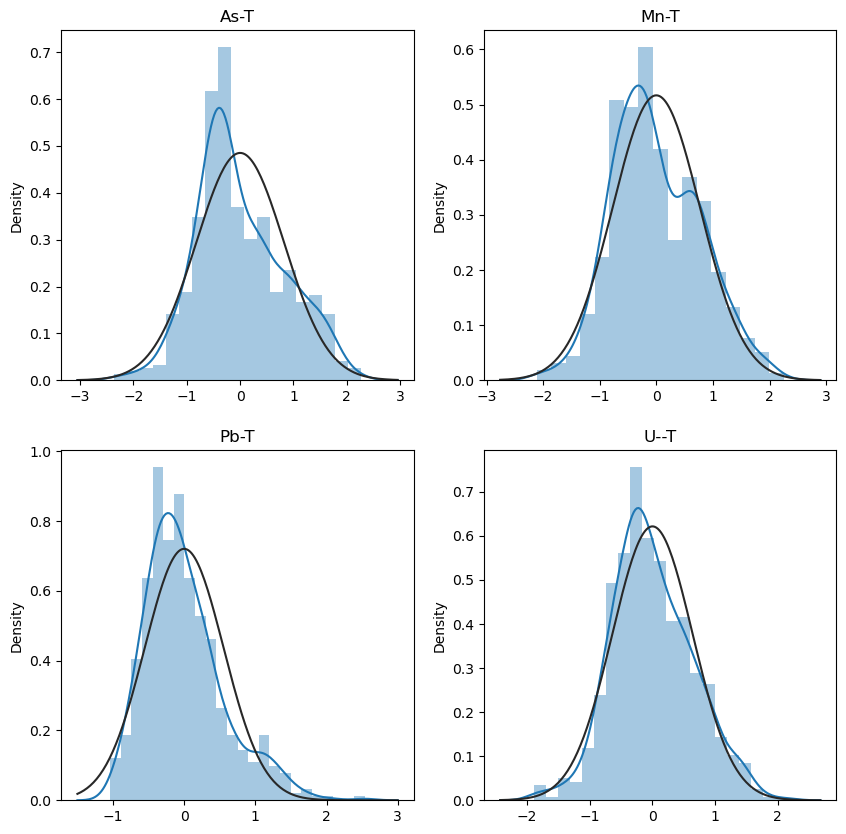

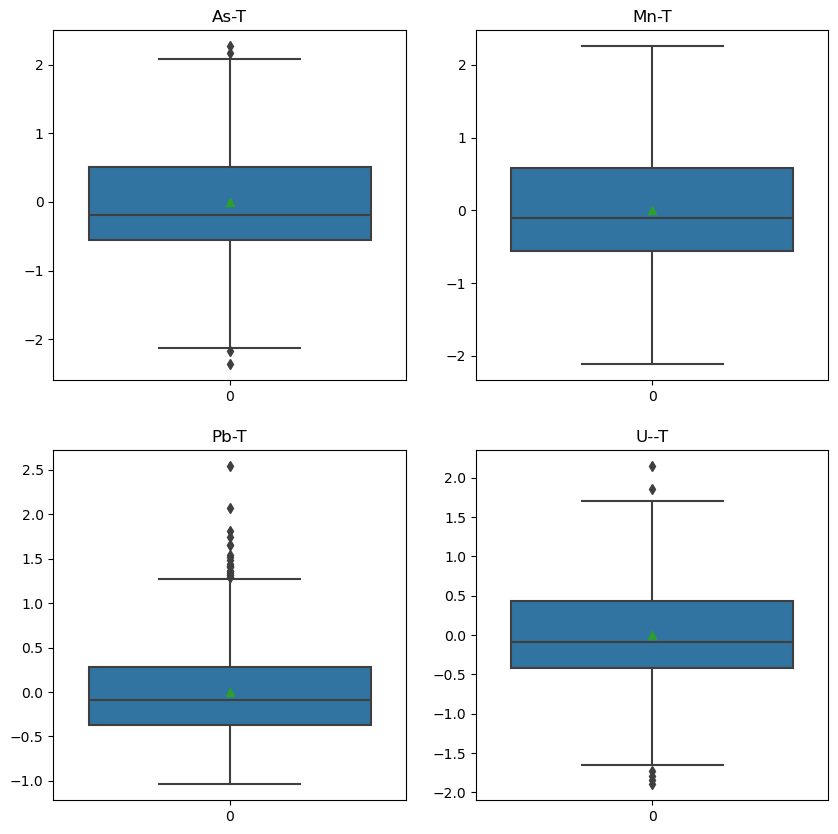

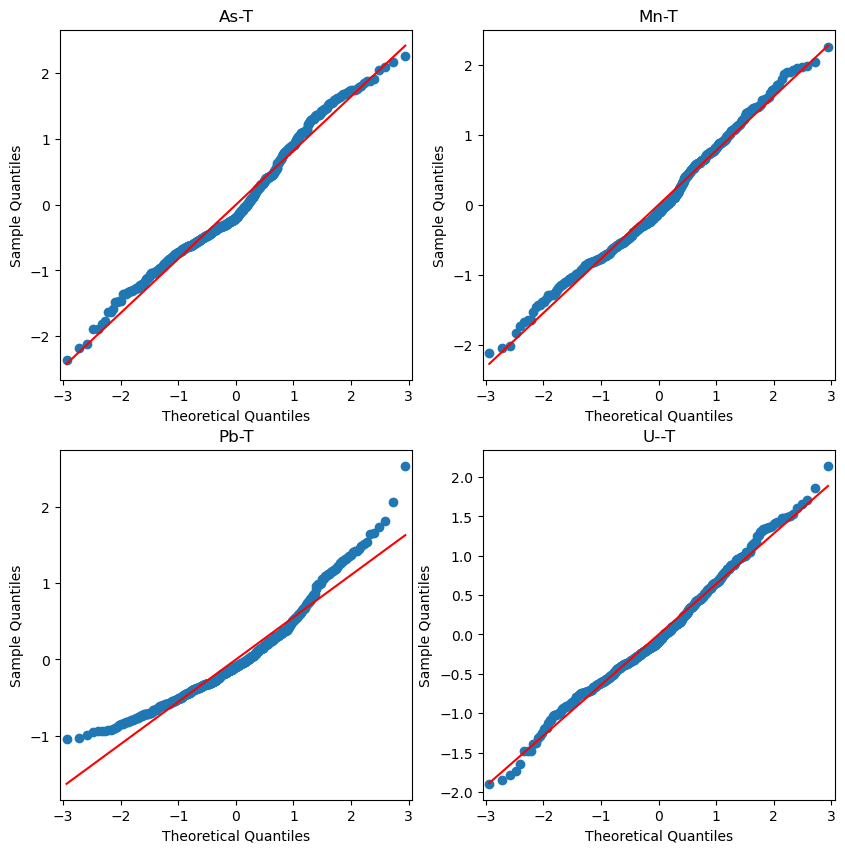

Text(0.5, 1.0, 'U--T')

In [18]:
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Plot each set of residuals
fig, ax = plt.subplots(2, 2, figsize=(10,10))

sns.distplot(ksa4_res.resid, fit=stats.norm, ax=ax[0,0])
sns.distplot(ksm4_res.resid, fit=stats.norm, ax=ax[0,1]) 
sns.distplot(ksp4_res.resid, fit=stats.norm, ax=ax[1,0])
sns.distplot(ksu4_res.resid, fit=stats.norm, ax=ax[1,1])

ax[0,0].set_title('As-T')
ax[0,1].set_title('Mn-T')
ax[1,0].set_title('Pb-T') 
ax[1,1].set_title('U--T')

plt.show()

# Boxplots
fig, ax = plt.subplots(2, 2, figsize=(10,10))

sns.boxplot(ksa4_res.resid.reset_index(drop=True), showmeans=True, ax=ax[0,0])
sns.boxplot(ksm4_res.resid.reset_index(drop=True), showmeans=True, ax=ax[0,1])
sns.boxplot(ksp4_res.resid.reset_index(drop=True), showmeans=True, ax=ax[1,0])
sns.boxplot(ksu4_res.resid.reset_index(drop=True), showmeans=True, ax=ax[1,1])

ax[0,0].set_title('As-T')
ax[0,1].set_title('Mn-T')
ax[1,0].set_title('Pb-T') 
ax[1,1].set_title('U--T')

plt.show()

# QQPlots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(10,10))

sm.qqplot(ksa4_res.resid, line='s', ax=ax1)
sm.qqplot(ksm4_res.resid, line='s', ax=ax2)
sm.qqplot(ksp4_res.resid, line='s', ax=ax3)
sm.qqplot(ksu4_res.resid, line='s', ax=ax4)

ax1.set_title('As-T')
ax2.set_title('Mn-T')
ax3.set_title('Pb-T') 
ax4.set_title('U--T')

plt.show()
ax[1,1].set_title('U--T')


In [19]:
'''
Min temp
'''
Asdrop = ['U--T','Pb-T','Mn-T']
Mndrop = ['As-T','Pb-T','U--T']
Pbdrop = ['As-T','U--T','Mn-T']
Udrop = ['As-T','Pb-T','Mn-T']
AsOther5 =DatatMT.drop(Asdrop, axis=1, errors='ignore')
MnOther5= DatatMT.drop(Mndrop, axis=1, errors='ignore')
PbOther5= DatatMT.drop(Pbdrop, axis=1, errors='ignore')
UOther5 = DatatMT.drop(Udrop, axis=1, errors='ignore')
AsOther5.columns = AsOther5.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
MnOther5.columns = MnOther5.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
PbOther5.columns = PbOther5.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
UOther5.columns = UOther5.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')


ksa5 =  smf.ols('As_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=AsOther5)
ksa5_res = ksa5.fit()
#ksa1_res.summary()

ksm5 =  smf.ols('Mn_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=MnOther5)
ksm5_res = ksm5.fit()

ksp5 =  smf.ols('Pb_T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=PbOther5)
ksp5_res = ksp5.fit()
#ksp1_res.summary()

ksu5 =  smf.ols('U__T ~ Alkalinity_Total_4_5 + Chlrid_D + Fe_T + N_Kjel_T + P__T + Residue_Filterable_1_0u + Specific_Conductance + Sulfat_D + pH + K__T + PRECIPITATION + MIN_TEMP + MAX_TEMP + Aquifer_1 + Aquifer_2 + Aquifer_3 + x + y + Months_Since_First_Sample', data=UOther5)
ksu5_res = ksu5.fit()
#ksu1_res.summary()

print("MT Summary of ksa5 model:\n", ksa5_res.summary())
print("MT Summary of ksm5 model:\n", ksm5_res.summary())
print("MT Summary of ksp5 model:\n", ksp5_res.summary())
print("MT Summary of ksu5 model:\n", ksu5_res.summary())

MT Summary of ksa5 model:
                             OLS Regression Results                            
Dep. Variable:                   As_T   R-squared:                       0.349
Model:                            OLS   Adj. R-squared:                  0.332
Method:                 Least Squares   F-statistic:                     20.68
Date:                Wed, 27 Dec 2023   Prob (F-statistic):           2.52e-53
Time:                        14:14:16   Log-Likelihood:                -858.59
No. Observations:                 713   AIC:                             1755.
Df Residuals:                     694   BIC:                             1842.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\3251014886.py:12: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  AsOther5.columns = AsOther5.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\3251014886.py:13: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  MnOther5.columns = MnOther5.columns.str.replace(' ', '_').str.replace('-', '_').str.replace(':', '_').str.replace('.', '_')
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\3251014886.py:14: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single chara

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\3021653029.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ksa5_res.resid, fit=stats.norm, ax=ax[0,0])
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_38828\3021653029.py:10: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ksm5_res.re

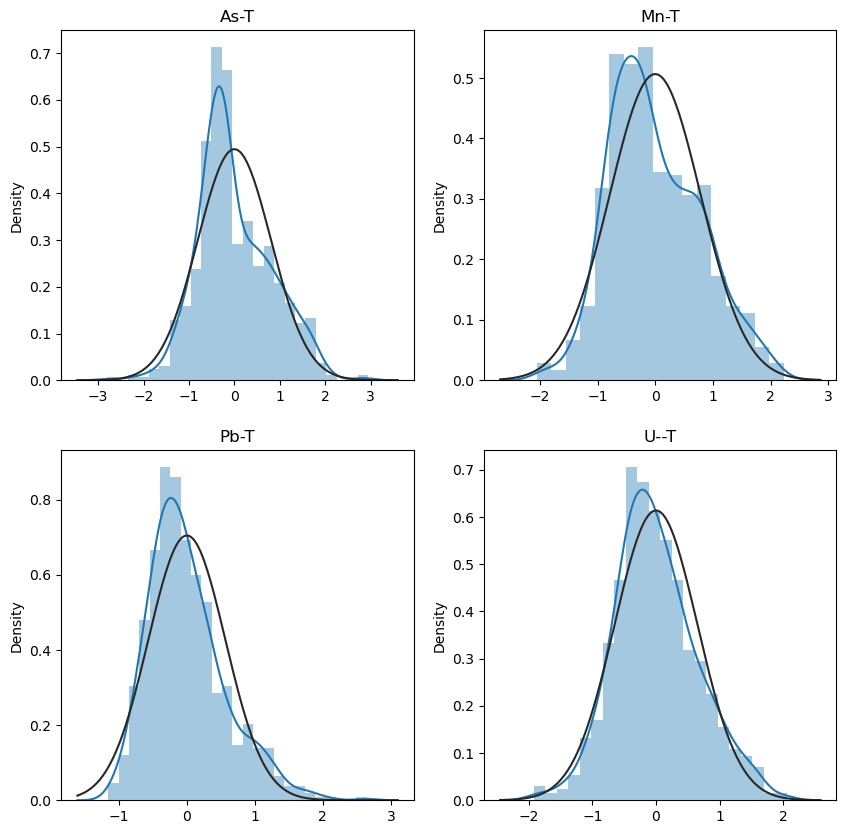

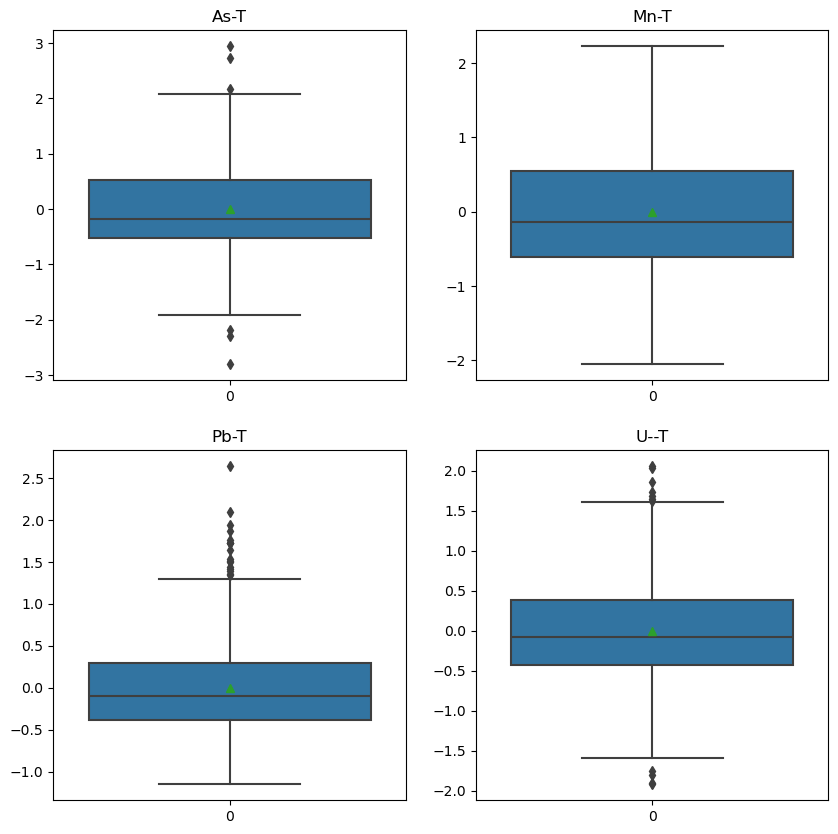

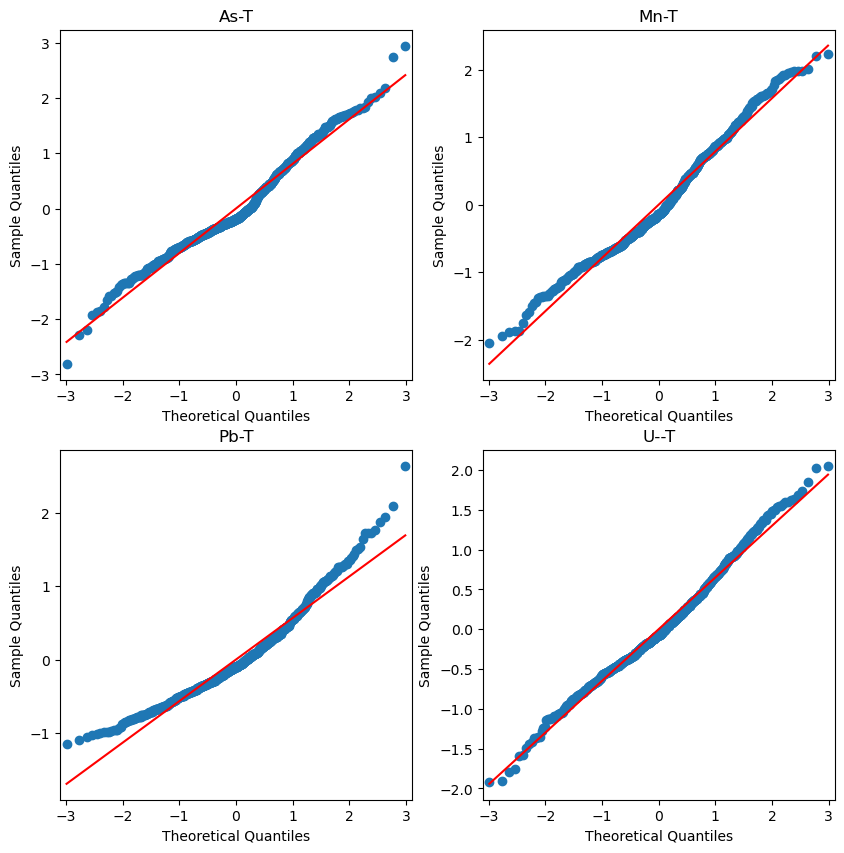

In [20]:
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Plot each set of residuals
fig, ax = plt.subplots(2, 2, figsize=(10,10))

sns.distplot(ksa5_res.resid, fit=stats.norm, ax=ax[0,0])
sns.distplot(ksm5_res.resid, fit=stats.norm, ax=ax[0,1]) 
sns.distplot(ksp5_res.resid, fit=stats.norm, ax=ax[1,0])
sns.distplot(ksu5_res.resid, fit=stats.norm, ax=ax[1,1])

ax[0,0].set_title('As-T')
ax[0,1].set_title('Mn-T')
ax[1,0].set_title('Pb-T') 
ax[1,1].set_title('U--T')

plt.show()

# Boxplots
fig, ax = plt.subplots(2, 2, figsize=(10,10))

sns.boxplot(ksa5_res.resid.reset_index(drop=True), showmeans=True, ax=ax[0,0])
sns.boxplot(ksm5_res.resid.reset_index(drop=True), showmeans=True, ax=ax[0,1])
sns.boxplot(ksp5_res.resid.reset_index(drop=True), showmeans=True, ax=ax[1,0])
sns.boxplot(ksu5_res.resid.reset_index(drop=True), showmeans=True, ax=ax[1,1])

ax[0,0].set_title('As-T')
ax[0,1].set_title('Mn-T')
ax[1,0].set_title('Pb-T') 
ax[1,1].set_title('U--T')

plt.show()

# QQPlots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(10,10))

sm.qqplot(ksa5_res.resid, line='s', ax=ax1)
sm.qqplot(ksm5_res.resid, line='s', ax=ax2)
sm.qqplot(ksp5_res.resid, line='s', ax=ax3)
sm.qqplot(ksu5_res.resid, line='s', ax=ax4)

ax1.set_title('As-T')
ax2.set_title('Mn-T')
ax3.set_title('Pb-T') 
ax4.set_title('U--T')

plt.show()